# Land classification on EuroSAT

In this notebook I use different models to classify Sentinel-2 satellite images from EuroSAT and compare their performance. Concretely, I will compare the following approaches:
1. **CNN trained from scratch**: a small standard model consisting of three convolutional blocks and a linear head (~175 K parameters)
2. **ResNet-18 with frozen backbone**: features pre-trained on ImageNet, and training of the final adapted layer (~5 K parameters)
3. **ResNet-18 with full fine-tuning**: training of the whole model, starting from the pre-trained weights (~11 M parameters)

**Results:** full fine-tuning the ResNet-18 model shows the best performance among the three (with around 3-5 percentage points better accuracy than the other ones), while not needing any substantial increase in computation time on a GPU.

In [1]:
# reload src/utils.py automatically when it is edited
%load_ext autoreload
%autoreload 2

import torchvision.datasets as datasets
import torchvision.transforms as transforms
import torch
from torch.utils.data import DataLoader, Subset
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from torchvision.models import resnet18, ResNet18_Weights

# training / evaluation loops, in ../src/utils.py
import sys
sys.path.append("../src")
from utils import fit, evaluate

## 1. Data Loading and normalisation
We use the RGB version of EuroSAT: 27,000 Sentinel-2 image patches of 64 × 64 pixels, labelled into 10 land-use / land-cover classes. 

In [2]:
transform = transforms.Compose([
    transforms.ToTensor(),
])

# Download and load the EuroSAT dataset (RGB version)
dataset = datasets.EuroSAT(
    root="../data/raw/EuroSAT",
    transform=transform,
    download=True,
)

In [3]:
device = "cuda" if torch.cuda.is_available() else "cpu"
print(device)

cuda


In [4]:
generator = torch.Generator().manual_seed(0)
train_set, val_set, test_set = torch.utils.data.random_split(
    dataset, [.8, .1, .1], generator = generator)


With the aim of making training more stable, let us first normalise the images. To this end we compute the per-channel mean and standard deviation on the training set only, so that no information from the validation or test images leaks into training.

In [5]:
# create data loader for training data
stats_dataloader = DataLoader(train_set, batch_size = 512, shuffle = False)

In [ ]:
# compute normalisation statistics
s = torch.zeros(3, dtype=torch.float64)
s2 = torch.zeros(3, dtype=torch.float64)
N = 0
for batch, label in stats_dataloader:
    batch = batch.double()
    s += batch.sum(dim = (0, 2, 3))    # batch has shape [512, 3, 64, 64] : [images, channels, height, width]
    s2 += (batch ** 2).sum(dim = (0, 2, 3))
    N += batch.shape[0] * batch.shape[2] * batch.shape[3]

mean = s / N
stdv = (s2 / N - mean ** 2) ** .5

print("mean:", mean)
print("stdv:", stdv)

mean: tensor([0.3433, 0.3797, 0.4075], dtype=torch.float64)
stdv: tensor([0.2017, 0.1364, 0.1152], dtype=torch.float64)


Define the normalisation transform for the dataset. This will not change the images themselves, but rather transform them whenever they are requested from the dataset.

In [7]:
dataset.transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean.tolist(), stdv.tolist())
])

Create the data loaders with batches of 64 images. While the training data is shuffled to guarantee that each epoch sees the images in a different order, validation and test are not, so that they are always evaluated in the same order.


In [8]:
loader_gen = torch.Generator().manual_seed(0)
train_dataloader = DataLoader(train_set, batch_size = 64, shuffle = True, generator = loader_gen)
val_dataloader = DataLoader(val_set, batch_size = 64, shuffle = False, generator = loader_gen)
test_dataloader = DataLoader(test_set, batch_size = 64, shuffle = False, generator = loader_gen)

Plot some images from the training set

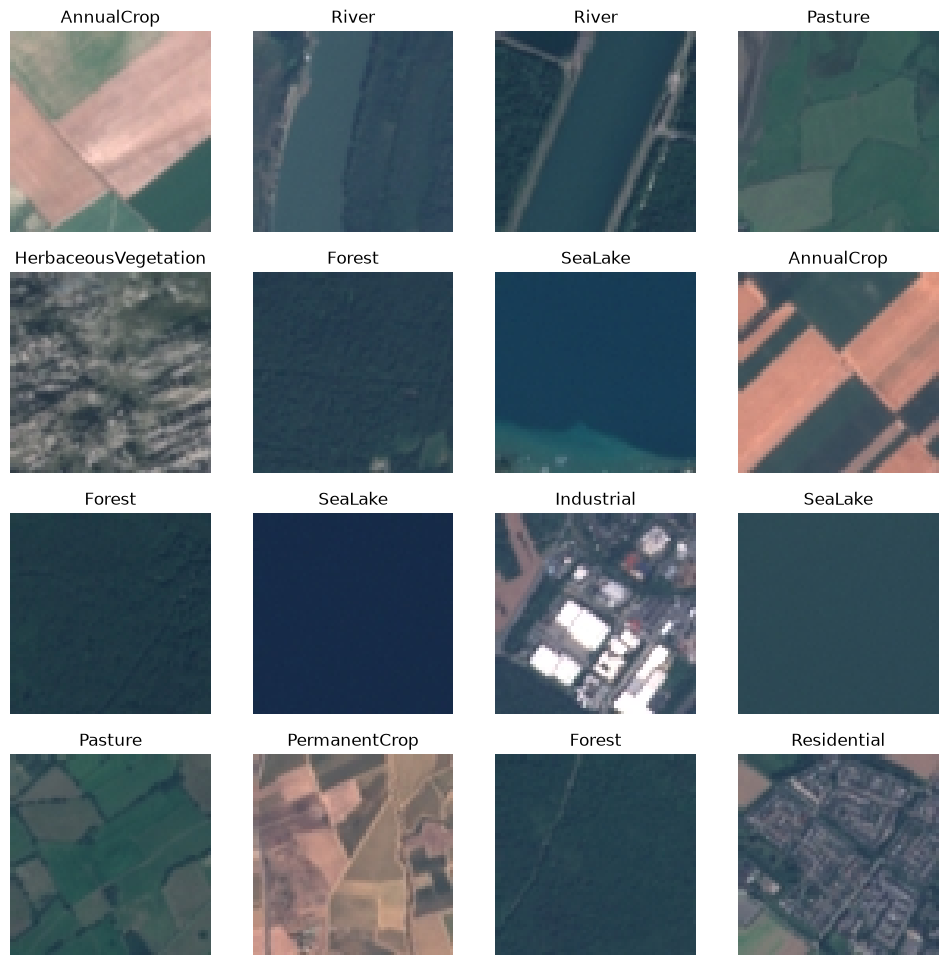

In [9]:
mean_t = mean.float().view(3, 1, 1)
std_t  = stdv.float().view(3, 1, 1)


figure = plt.figure(figsize=(12, 12))
cols, rows = 4, 4
for i in range(1, cols * rows + 1):
    sample_idx = torch.randint(len(train_set), size=(1,)).item()
    img, label = train_set[sample_idx]
    img = (img * std_t + mean_t).clamp(0, 1)

    # torch and matplotlib have different channel orders, so permute the image tensor
    img = img.permute(1, 2, 0)
    figure.add_subplot(rows, cols, i)
    plt.title(dataset.classes[label])
    plt.axis("off")
    plt.imshow(img)  

plt.show()

## 2. The CNN model

CNNs are the standard tool for classifying images, as they keep pixel neighbourhoods and are able to learn patterns using shared filters, thus needing far fewer parameters than fully connected networks. For 64 × 64 pixel inputs such as EuroSAT ones, we implement a common small CNN consisting of three convolution blocks (Conv 3×3 → BatchNorm → ReLU → MaxPool) with 32 → 64 → 128 channels, followed by dropout (0.3) and a linear head. 


In [10]:
from torch import nn

def conv_block(in_channels, out_channels):
    return nn.Sequential(
        nn.Conv2d(in_channels, out_channels, kernel_size = 3, padding = 1, bias = False),
        nn.BatchNorm2d(out_channels),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size = 2)
    )


class CNN(nn.Module):
    def __init__(self, n_classes = 10):
        super().__init__()
        self.features = nn.Sequential(
            conv_block(3, 32),
            conv_block(32, 64),
            conv_block(64, 128)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.3),
            nn.Linear(128 * 8 * 8, n_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x


### Training functions
The training and evaluation loops are shared by all three models, so they live in [`src/utils.py`](../src/utils.py) and are imported at the top of the notebook:
- `evaluate`: computes loss and accuracy without updating the weights.
- `fit`: trains the model for `n_epochs` with Adam (optionally with a cosine learning-rate schedule), evaluates it on the validation set after each epoch, saves the weights of the best validation epoch, and returns the metrics of every epoch as a DataFrame.

Test the model with a single batch, before training on the full dataset. If everything works properly, the model should be able to overfit it and thus the loss should drop close to zero.


In [13]:
model = CNN().to(device)
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr = 1e-3)

X, y = next(iter(train_dataloader))
X = X.to(device)
y = y.to(device)

model.train()
Nsteps = 100
for step in range(Nsteps):
    loss = loss_fn(model(X), y)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    if step % 10 == 0:
        print(step, loss.item())


0 2.441251754760742
10 0.26786428689956665
20 0.04208257049322128
30 0.02442975901067257
40 0.005183341912925243
50 0.0029454478062689304
60 0.0018184311920776963
70 0.0016228940803557634
80 0.0012072105892002583
90 0.0009816082892939448


### Train the model

Let us first try with a constant learning rate

In [14]:
torch.manual_seed(0)
model = CNN().to(device)

metrics_const = fit(model, train_dataloader, val_dataloader, loss_fn,
                    n_epochs = 15, lr = 1e-3, device = device,
                    cosine_schedule = False, verbose = True)

 0:   lr 1.0e-03,   train 0.961/0.684,   validation 0.806 / 0.742
 1:   lr 1.0e-03,   train 0.621/0.798,   validation 0.797 / 0.780
 2:   lr 1.0e-03,   train 0.480/0.842,   validation 0.496 / 0.843
 3:   lr 1.0e-03,   train 0.406/0.863,   validation 0.415 / 0.869
 4:   lr 1.0e-03,   train 0.343/0.886,   validation 0.390 / 0.876
 5:   lr 1.0e-03,   train 0.306/0.896,   validation 0.397 / 0.881
 6:   lr 1.0e-03,   train 0.270/0.908,   validation 0.352 / 0.891
 7:   lr 1.0e-03,   train 0.232/0.921,   validation 0.337 / 0.889
 8:   lr 1.0e-03,   train 0.222/0.924,   validation 0.361 / 0.887
 9:   lr 1.0e-03,   train 0.180/0.937,   validation 0.298 / 0.911
10:   lr 1.0e-03,   train 0.172/0.941,   validation 0.366 / 0.887
11:   lr 1.0e-03,   train 0.164/0.942,   validation 0.320 / 0.907
12:   lr 1.0e-03,   train 0.133/0.953,   validation 0.384 / 0.887
13:   lr 1.0e-03,   train 0.144/0.948,   validation 0.349 / 0.909
14:   lr 1.0e-03,   train 0.124/0.957,   validation 0.318 / 0.906


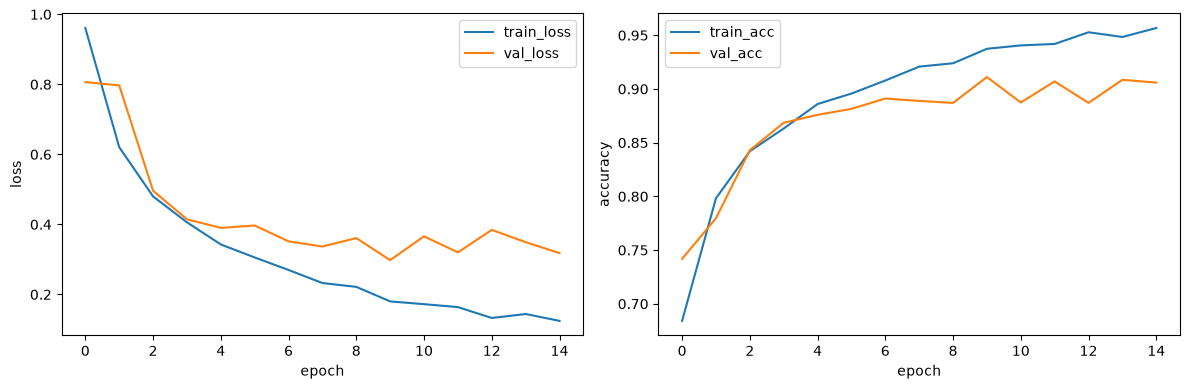

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
metrics_const[["train_loss", "val_loss"]].plot(ax=axes[0], ylabel="loss")
metrics_const[["train_acc", "val_acc"]].plot(ax=axes[1], ylabel="accuracy")
plt.tight_layout()
plt.show()

Validation bounces heavily, indicating that the constant learning rate is too large at the final epochs and the weights keep overshooting near the optimum. Picking the best epoch from such a noisy curve gives a rather optimistic estimate: let's try with a learning-rate schedule instead

In [16]:
torch.manual_seed(0)
model = CNN().to(device)

metrics_cos = fit(model, train_dataloader, val_dataloader, loss_fn,
                 n_epochs = 15, lr = 1e-3, device = device,
                 cosine_schedule = True,
                 ckpt_path = "../data/processed/eurosat_cnn_best.pt",
                 verbose = True)

 0:   lr 1.0e-03,   train 0.969/0.677,   validation 0.692 / 0.782
 1:   lr 9.9e-04,   train 0.582/0.804,   validation 0.541 / 0.834
 2:   lr 9.6e-04,   train 0.474/0.840,   validation 0.519 / 0.831
 3:   lr 9.0e-04,   train 0.390/0.865,   validation 0.404 / 0.870
 4:   lr 8.3e-04,   train 0.328/0.887,   validation 0.370 / 0.883
 5:   lr 7.5e-04,   train 0.282/0.902,   validation 0.374 / 0.874
 6:   lr 6.5e-04,   train 0.218/0.924,   validation 0.307 / 0.904
 7:   lr 5.5e-04,   train 0.194/0.932,   validation 0.301 / 0.893
 8:   lr 4.5e-04,   train 0.159/0.943,   validation 0.338 / 0.888
 9:   lr 3.5e-04,   train 0.132/0.955,   validation 0.264 / 0.915
10:   lr 2.5e-04,   train 0.111/0.962,   validation 0.222 / 0.922
11:   lr 1.7e-04,   train 0.094/0.968,   validation 0.220 / 0.920
12:   lr 9.5e-05,   train 0.080/0.975,   validation 0.208 / 0.930
13:   lr 4.3e-05,   train 0.070/0.978,   validation 0.198 / 0.934
14:   lr 1.1e-05,   train 0.067/0.979,   validation 0.200 / 0.932


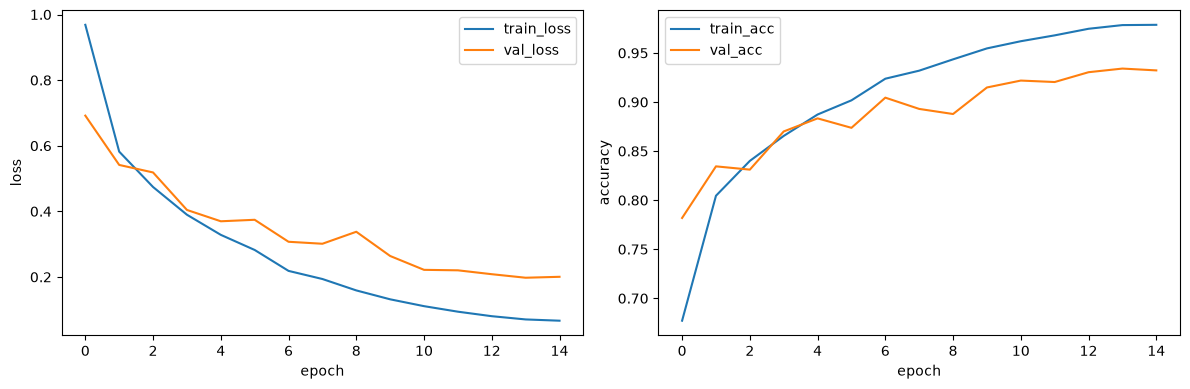

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
metrics_cos[["train_loss", "val_loss"]].plot(ax=axes[0], ylabel="loss")
metrics_cos[["train_acc", "val_acc"]].plot(ax=axes[1], ylabel="accuracy")
plt.tight_layout()
plt.show()

The validation curve settles as the learning rate drops, and its accuracy reaches a plateau with a rather small variation at the final epochs, so the kept checkpoint is no longer a lucky spike.

### Test the model

In [18]:
# load the optimal model
path = "../data/processed/eurosat_cnn_best.pt"
model = CNN().to(device)
model.load_state_dict(torch.load(path, weights_only = True))

# evaluate it on the test set
test_loss, test_acc = evaluate(model, test_dataloader, loss_fn, device)

# compute the 95% confidence interval for the accuracy
std_error = np.sqrt(test_acc * (1 - test_acc) / len(test_dataloader.dataset))
ci = 1.96 * std_error

print("test loss:", np.round(test_loss, 3))
print("test accuracy:", np.round(test_acc, 3))
print("95% CI for test accuracy: [", np.round(test_acc - ci, 3), ",", np.round(test_acc + ci, 3), "]")


test loss: 0.173
test accuracy: 0.943
95% CI for test accuracy: [ 0.934 , 0.951 ]


The trained model obtains around a 94% accuracy on the test data. Let us break it down and look how it performs for each class, and compute the confusion matrix.

per class recall (correct / true count):
Highway                 0.864
PermanentCrop           0.907
River                   0.913
HerbaceousVegetation    0.926
AnnualCrop              0.940
Pasture                 0.966
Industrial              0.966
Forest                  0.968
SeaLake                 0.979
Residential             0.989
dtype: float64


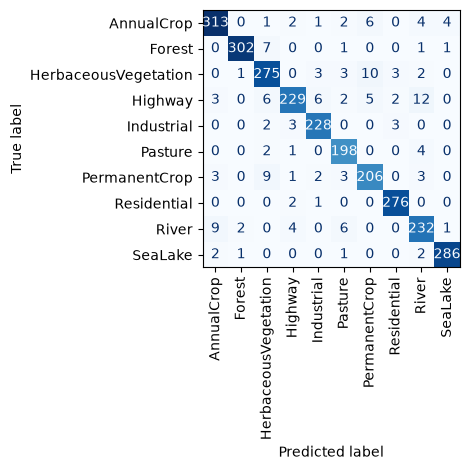

In [19]:
# collect predictions from the test set
model.eval()
y_true = []
y_pred = []
with torch.no_grad():
    for X, y in test_dataloader:
        logits = model (X.to(device))
        y_pred.append(logits.argmax(dim = 1).cpu())
        y_true.append(y)
y_true = torch.cat(y_true).numpy()
y_pred = torch.cat(y_pred).numpy()

# compute confusion matrix and per-class recall
cm = confusion_matrix(y_true, y_pred)
per_class_acc = cm.diagonal() / cm.sum(axis = 1)



print("per class recall (correct / true count):")
print(pd.Series(per_class_acc, index=dataset.classes).sort_values().round(3))

disp = ConfusionMatrixDisplay(confusion_matrix = cm, display_labels = dataset.classes)
disp.plot(colorbar = False, xticks_rotation = 90, cmap = "Blues")
plt.tight_layout()

From the per-class recall we see that the model learns more homogeneous areas better: large bodies of water or residential areas are almost perfectly identified. On the other hand, classes characterised by distinct thin features, such as a river's edge or a highway, are harder to learn.

## 3. Transfer learning with ResNet-18

Let us now try to use a bigger, pre-trained model. It has around ~11 M parameters and was trained with the ImageNet image set to identify all kind of images, not specifically satellite ones. There are two main ways to use a pre-trained model:
- Frozen backbone: we keep the pre-trained weights on the whole network except for those in the final layer. The internal layers already know how to identify patterns, colours, textures... so training only the last fully connected layer can sometimes yield good accuracy levels while heavily cutting off the amount of parameters to be trained. This usually suffices when the new images resemble the original training data.
- Full fine-tuning. Starting from the pre-trained weights, fine-tune all of them to try to find a more optimal point. This can sometimes be costly but usually yields much better accuracies (though can sometimes overfit), specially when the new image set is very different to the original one on which the model was trained.

 ### Normalisation
 Since the pre-trained weights were obtained for ImageNet's images, before feeding EuroSAT's ones to the model they must be normalised to ImageNet's statistics. We reuse the same split indices as before, so all three models are trained, validated and tested on exactly the same images.


In [20]:
# define the normalisation to the pre-trained ResNet18 model
weights = ResNet18_Weights.DEFAULT
imagenet_mean = weights.transforms().mean
imagenet_std  = weights.transforms().std
imagenet_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(imagenet_mean, imagenet_std)
])

# define the dataset of EuroSAT images normalised with ImageNet statistics
dataset_imagenet = datasets.EuroSAT(root = "../data/raw/EuroSAT", transform = imagenet_transform)

# reuse indices to define the new sets, to ensure the exact same images are used 
train_set_imagenet = Subset(dataset_imagenet, train_set.indices)
val_set_imagenet = Subset(dataset_imagenet, val_set.indices)
test_set_imagenet = Subset(dataset_imagenet, test_set.indices)

# define the new dataloaders
train_dataloader_imagenet = DataLoader(train_set_imagenet, batch_size = 64, shuffle = True)
val_dataloader_imagenet = DataLoader(val_set_imagenet, batch_size = 64, shuffle = False)
test_dataloader_imagenet = DataLoader(test_set_imagenet, batch_size = 64, shuffle = False)


### Adapt the ResNet-18 model
ResNet-18 final layer maps 512 features to the 1000 ImageNet classes, so we need to swap it for a 10-output one in order to match the 10-class classification of the EuroSAT sets.

In [21]:
# build a ResNet-18 model with pre-trained weights but a final 10-output layer
def build_resnet18(n_classes = 10):
    model = resnet18(weights = ResNet18_Weights.DEFAULT)
    model.fc = nn.Linear(model.fc.in_features, n_classes)
    return model

### Frozen Backbone model

Let us first try with a frozen backbone model that keeps the weights of all ResNet-18 pre-trained layers and trains only the last 10-output layer's ones. BatchNorm layers stay in eval mode so that the backbone's ImageNet normalisation statistics are not overwritten.

In [22]:
class FrozenBackbone(nn.Module):
    def __init__(self, model):
        super().__init__()
        self.model = model

        # freeze the learned weights for all tensors except the final layer
        for name, p in self.model.named_parameters():
            p.requires_grad = name.startswith("fc.")

    def train(self, mode=True):
        # set mode on every submodule
        super().train(mode)      

        # set eval() mode for every BatchNorm                
        for m in self.model.modules():
            if isinstance(m, nn.BatchNorm2d):
                m.eval()                         
        return self

    def forward(self, x):
        return self.model(x)


Train the frozen backbone model

In [23]:
torch.manual_seed(0)
model_frozen = FrozenBackbone(build_resnet18()).to(device)

metrics_frozen = fit(model_frozen, train_dataloader_imagenet, val_dataloader_imagenet, 
                     loss_fn, n_epochs = 15, lr = 1e-3, device=device,
                     ckpt_path = "../data/processed/eurosat_resnet18_frozen_best.pt",
                     verbose = True)

 0:   lr 1.0e-03,   train 0.491/0.849,   validation 0.324 / 0.897
 1:   lr 9.9e-04,   train 0.273/0.909,   validation 0.290 / 0.898
 2:   lr 9.6e-04,   train 0.237/0.919,   validation 0.261 / 0.912
 3:   lr 9.0e-04,   train 0.219/0.926,   validation 0.257 / 0.914
 4:   lr 8.3e-04,   train 0.203/0.931,   validation 0.251 / 0.915
 5:   lr 7.5e-04,   train 0.192/0.934,   validation 0.245 / 0.919
 6:   lr 6.5e-04,   train 0.184/0.937,   validation 0.251 / 0.918
 7:   lr 5.5e-04,   train 0.177/0.940,   validation 0.258 / 0.916
 8:   lr 4.5e-04,   train 0.170/0.943,   validation 0.239 / 0.920
 9:   lr 3.5e-04,   train 0.164/0.945,   validation 0.237 / 0.919
10:   lr 2.5e-04,   train 0.160/0.947,   validation 0.237 / 0.920
11:   lr 1.7e-04,   train 0.157/0.948,   validation 0.236 / 0.922
12:   lr 9.5e-05,   train 0.154/0.950,   validation 0.234 / 0.924
13:   lr 4.3e-05,   train 0.152/0.950,   validation 0.235 / 0.921
14:   lr 1.1e-05,   train 0.151/0.951,   validation 0.235 / 0.923


And just as a sanity-check, check that the backbone stayed frozen

In [24]:
reference = build_resnet18().to(device)
print("conv1 unchanged:", torch.equal(reference.conv1.weight, model_frozen.model.conv1.weight))
print("bn1 stats unchanged:", torch.equal(reference.bn1.running_mean, model_frozen.model.bn1.running_mean))


conv1 unchanged: True
bn1 stats unchanged: True


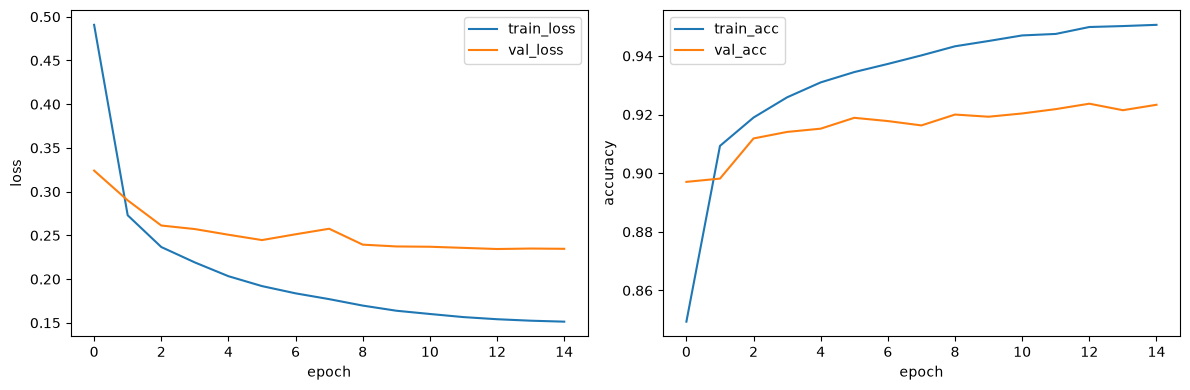

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
metrics_frozen[["train_loss", "val_loss"]].plot(ax=axes[0], ylabel="loss")
metrics_frozen[["train_acc", "val_acc"]].plot(ax=axes[1], ylabel="accuracy")
plt.tight_layout()
plt.show()

Looking at the validation accuracy we see that the frozen bacbkone model learns fast but reaches a plateau at around 92%, below what the CNN trained from scracth was able to yield. ImageNet features are composed of everyday objects, and thus training only the final layer of ~5 K parameters does not give the model enough flexibility to fully adapt to the satellite images.


### Full fine-tuning
Let us now fine-tune all layers of the pre-trained ResNet-18. We now set a smaller initial learning rate, as the pre-trained weights presumably already sit near a good solution and a larger rate could potentially push them away.

In [26]:
torch.manual_seed(0)
model_ft = build_resnet18().to(device)

metrics_ft = fit(model_ft, train_dataloader_imagenet, val_dataloader_imagenet,
                 loss_fn, n_epochs = 15, lr = 1e-4, device = device,
                 ckpt_path = "../data/processed/eurosat_resnet18_finetuned_best.pt",
                 verbose = True)

 0:   lr 1.0e-04,   train 0.307/0.901,   validation 0.120 / 0.956
 1:   lr 9.9e-05,   train 0.079/0.975,   validation 0.115 / 0.961
 2:   lr 9.6e-05,   train 0.043/0.986,   validation 0.107 / 0.967
 3:   lr 9.0e-05,   train 0.030/0.990,   validation 0.112 / 0.969
 4:   lr 8.3e-05,   train 0.024/0.993,   validation 0.116 / 0.970
 5:   lr 7.5e-05,   train 0.015/0.995,   validation 0.126 / 0.970
 6:   lr 6.5e-05,   train 0.010/0.997,   validation 0.111 / 0.973
 7:   lr 5.5e-05,   train 0.008/0.997,   validation 0.106 / 0.973
 8:   lr 4.5e-05,   train 0.007/0.998,   validation 0.106 / 0.974
 9:   lr 3.5e-05,   train 0.004/0.999,   validation 0.105 / 0.973
10:   lr 2.5e-05,   train 0.004/0.999,   validation 0.105 / 0.974
11:   lr 1.7e-05,   train 0.002/0.999,   validation 0.099 / 0.976
12:   lr 9.5e-06,   train 0.001/1.000,   validation 0.097 / 0.977
13:   lr 4.3e-06,   train 0.001/1.000,   validation 0.098 / 0.979
14:   lr 1.1e-06,   train 0.002/1.000,   validation 0.097 / 0.976


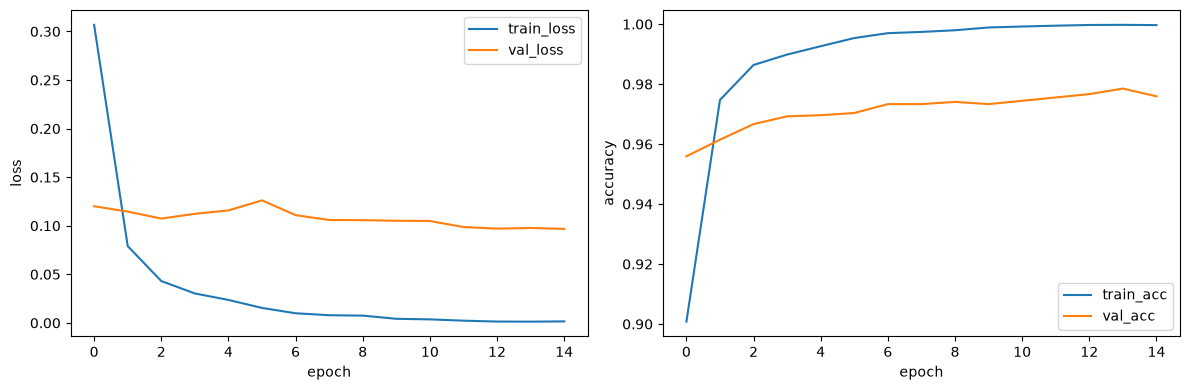

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
metrics_ft[["train_loss", "val_loss"]].plot(ax=axes[0], ylabel="loss")
metrics_ft[["train_acc", "val_acc"]].plot(ax=axes[1], ylabel="accuracy")
plt.tight_layout()
plt.show()

## 4. Comparison between the three models
Let us now grab the results from the three models and compare them side by side. To this end we first plot the validation accuracy at each epoch and then summarise each model's best saved checkpoint.

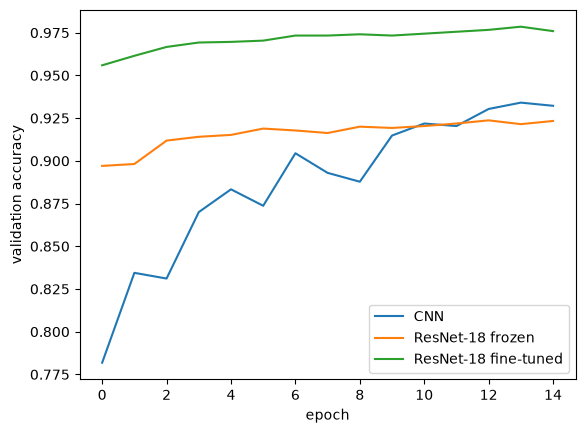

In [28]:
metrics_cos.val_acc.plot(label = "CNN")
metrics_frozen.val_acc.plot(label = "ResNet-18 frozen")
metrics_ft.val_acc.plot(label = "ResNet-18 fine-tuned")
plt.xlabel("epoch")
plt.ylabel("validation accuracy")
plt.legend()
plt.show()

In [29]:
# Rebuild each architecture and load its best checkpoint
cnn = CNN().to(device)
cnn.load_state_dict(torch.load("../data/processed/eurosat_cnn_best.pt", weights_only=True))

frozen = FrozenBackbone(build_resnet18()).to(device)
frozen.load_state_dict(torch.load("../data/processed/eurosat_resnet18_frozen_best.pt", weights_only=True))

finetuned = build_resnet18().to(device)
finetuned.load_state_dict(torch.load("../data/processed/eurosat_resnet18_finetuned_best.pt", weights_only=True))


def test_summary(name, model, test_loader, metrics):
    test_loss, test_acc = evaluate(model, test_loader, loss_fn, device)
    ci = 1.96 * np.sqrt(test_acc * (1 - test_acc) / len(test_loader.dataset))
    return {"model": name,
            "trainable_params": sum(p.numel() for p in model.parameters() if p.requires_grad),
            "best_val_acc": metrics["val_acc"].max(),
            "test_acc": test_acc,
            "test_ci95": ci,
            "sec_per_epoch": metrics["seconds"].mean()}


comparison = pd.DataFrame([
    test_summary("CNN", cnn, test_dataloader, metrics_cos),
    test_summary("ResNet-18 frozen", frozen, test_dataloader_imagenet, metrics_frozen),
    test_summary("ResNet-18 fine-tuned", finetuned, test_dataloader_imagenet, metrics_ft),
]).set_index("model").round(3)
comparison


,trainable_params,best_val_acc,test_acc,test_ci95,sec_per_epoch
model,,,,,
CNN,175402,0.934,0.943,0.009,15.470
ResNet-18 frozen,5130,0.924,0.920,0.010,15.999
ResNet-18 fine-tuned,11181642,0.979,0.973,0.006,15.235


Fine-tuning the pre-trained ResNet-18 yields the best test accuracy, beating all other models' final results even after a single epoch. Running on a GPU, no substantial change in the time spent per epoch is observed among models.